# 04 – Decision Threshold & Business Cost
Goal: choose the decision threshold that minimizes total business cost.

**Assumptions:** offer costs $20, a lost customer costs $300, and an offer saves 50% of targeted churners.

In [2]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict

from src.data import load_data
from src.features import NUMERIC_FEATURES, CATEGORICAL_FEATURES, TARGET
from src.model import build_model
from src.costs import cost_breakdown

df = load_data("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
X = df[NUMERIC_FEATURES + CATEGORICAL_FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(X_train.shape, X_test.shape)

(5634, 17) (1409, 17)


## Choosing the threshold (training set only)
Out-of-fold predictions: each training customer's probability comes from a model that did not see that customer.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_proba = cross_val_predict(
    build_model(), X_train, y_train, cv=cv, method="predict_proba"
)[:, 1]

print(oof_proba[:5].round(3))

[0.398 0.302 0.039 0.1   0.34 ]


In [4]:
thresholds = np.arange(0.02, 0.91, 0.01)
curve = pd.DataFrame([cost_breakdown(y_train, oof_proba, t) for t in thresholds])

best = curve.loc[curve["total_cost"].idxmin()]
print(f"Best threshold: {best['threshold']:.2f}  →  total cost ${best['total_cost']:,.0f}")

Best threshold: 0.12  →  total cost $306,410


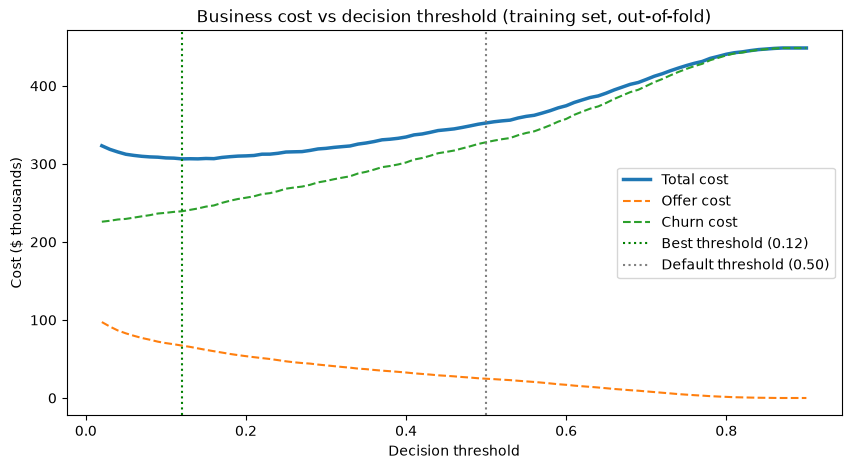

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(curve["threshold"], curve["total_cost"] / 1000, linewidth=2.5, label="Total cost")
ax.plot(curve["threshold"], curve["offer_cost"] / 1000, linestyle="--", label="Offer cost")
ax.plot(curve["threshold"], curve["churn_cost"] / 1000, linestyle="--", label="Churn cost")
ax.axvline(best["threshold"], color="green", linestyle=":", label=f"Best threshold ({best['threshold']:.2f})")
ax.axvline(0.5, color="gray", linestyle=":", label="Default threshold (0.50)")
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Cost ($ thousands)")
ax.set_title("Business cost vs decision threshold (training set, out-of-fold)")
ax.legend()
fig.savefig("../reports/figures/cost_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
comparison = pd.DataFrame([
    {"strategy": "Do nothing",            **cost_breakdown(y_train, oof_proba, 1.01)},
    {"strategy": "Offer to everyone",     **cost_breakdown(y_train, oof_proba, 0.0)},
    {"strategy": "Model, threshold 0.50", **cost_breakdown(y_train, oof_proba, 0.5)},
    {"strategy": "Model, best threshold", **cost_breakdown(y_train, oof_proba, best["threshold"])},
]).set_index("strategy")

comparison[["threshold", "TP", "FP", "FN", "offer_cost", "churn_cost", "total_cost"]]

,threshold,TP,FP,FN,offer_cost,churn_cost,total_cost
strategy,,,,,,,
Do nothing,1.01,0,0,1495,0,448500.0,448500.0
Offer to everyone,0.00,1495,4139,0,112680,224250.0,336930.0
"Model, threshold 0.50",0.50,805,429,690,24680,327750.0,352430.0
"Model, best threshold",0.12,1395,1963,100,67160,239250.0,306410.0


### Threshold results (training set, out-of-fold predictions)
- **Best threshold: 0.12**, close to the theoretical break-even of 20 / (0.5 × 300) ≈ 0.13.
- At the default 0.5 threshold the model costs **$352,430**, which is **worse than offering to everyone ($336,930)**. A good model with the wrong threshold can lose money.
- At 0.12 the cost drops to **$306,410**: **$46,020 less than the 0.5 threshold** and $30,520 less than offering to everyone.
- Recall rises from 54% to 93% (690 → 100 missed churners), at the cost of more false alarms (429 → 1,963). Cheap false alarms ($20) are worth it to avoid expensive missed churners ($300).
- The cost curve is flat around 0.08–0.20, so the result isn't sensitive to the exact threshold.

## Final evaluation on the test set
The model and threshold were chosen using training data only. The test set is used once, here, to check they work on unseen customers. The threshold is **not** re-tuned on the test set.

In [7]:
from sklearn.metrics import roc_auc_score, average_precision_score

final_model = build_model()
final_model.fit(X_train, y_train)

test_proba = final_model.predict_proba(X_test)[:, 1]

print(f"Test ROC-AUC: {roc_auc_score(y_test, test_proba):.3f}")
print(f"Test PR-AUC:  {average_precision_score(y_test, test_proba):.3f}")

Test ROC-AUC: 0.839
Test PR-AUC:  0.630


In [8]:
BEST_T = round(float(best["threshold"]), 2)

test_comparison = pd.DataFrame([
    {"strategy": "Do nothing",                 **cost_breakdown(y_test, test_proba, 1.01)},
    {"strategy": "Offer to everyone",          **cost_breakdown(y_test, test_proba, 0.0)},
    {"strategy": "Model, threshold 0.50",      **cost_breakdown(y_test, test_proba, 0.5)},
    {"strategy": f"Model, threshold {BEST_T}", **cost_breakdown(y_test, test_proba, BEST_T)},
]).set_index("strategy")

test_comparison[["threshold", "TP", "FP", "FN", "offer_cost", "churn_cost", "total_cost"]]

,threshold,TP,FP,FN,offer_cost,churn_cost,total_cost
strategy,,,,,,,
Do nothing,1.01,0,0,374,0,112200.0,112200.0
Offer to everyone,0.00,374,1035,0,28180,56100.0,84280.0
"Model, threshold 0.50",0.50,207,116,167,6460,81150.0,87610.0
"Model, threshold 0.12",0.12,349,483,25,16640,59850.0,76490.0


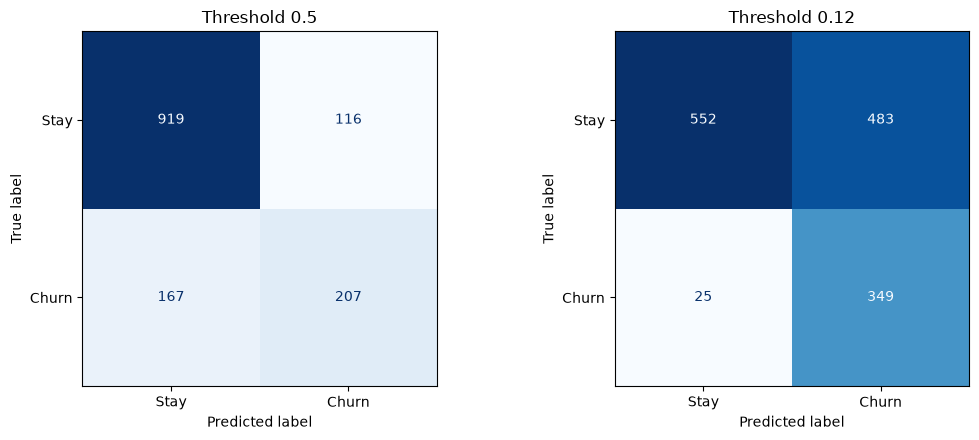

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, t in zip(axes, [0.5, BEST_T]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, (test_proba >= t).astype(int),
        display_labels=["Stay", "Churn"], cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(f"Threshold {t}")
plt.tight_layout()
plt.show()

In [10]:
import joblib

joblib.dump({"model": final_model, "threshold": BEST_T}, "../models/churn_model.joblib")
print("Saved model with threshold", BEST_T)

Saved model with threshold 0.12


### Final results (test set: 1,409 unseen customers)
- **The model generalizes:** test ROC-AUC 0.839 and PR-AUC 0.630, close to cross-validation (0.845 / 0.660).
- **Threshold 0.12 is the cheapest strategy:** $76,490 vs $84,280 (offer to everyone), $87,610 (threshold 0.5) and $112,200 (do nothing).
- **Savings:** $11,120 (12.7%) vs the default 0.5 threshold, about $79,000 per 10,000 customers.
- **The default 0.5 threshold is worse than offering everyone a discount**, on both training and test data. Choosing the threshold by business cost matters as much as the model itself.
- **Recall:** catches 93% of churners (349/374) vs 55% at 0.5, with 483 false alarms costing $20 each.

**Limitations:** results depend on the cost assumptions ($20 offer, $300 churn, 50% save rate). If these change, the best threshold changes too (break-even ≈ offer cost ÷ (save rate × churn cost)). The dataset is a fictional IBM sample.